# Results walkthrough

This notebook recomputes the paper's headline comparison from the saved out-of-fold detector scores. **Nothing is fitted** and no source table is needed.

It covers Study 3: 1,260 episodes (21 arms, ten source families, raw and deduplicated variants, three seeds). Three learned views are compared, each evaluated by leave-one-family-out:

| View | Reads |
|---|---|
| **S**, structural | data values, partitions and the declared preprocessing scope |
| **B**, behavioral | how the loss moves when the pipeline is refitted after a corrective edit |
| **SB**, combined | both |

The unit of inference is the source family, so every statistic below is computed per family first.

In [1]:
import itertools
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
RESEARCH = REPO / "research"
R8 = RESEARCH / "review_response_2026-11-03" / "round8"
print("repository root found:", (REPO / "research").is_dir())

repository root found: True


## 1. Ground truth and scores

Ground truth is stored apart from the features. An episode is positive if training and evaluation share source records or, for scope and proxy leakage, if the planted flow is present.

In [2]:
truth = pd.concat([pd.read_csv(f) for f in sorted((RESEARCH / "stage7_2026-11-02" / "s3").glob("*/episodes_truth.csv"))], ignore_index=True)
print(len(truth), "episodes;", int(truth.label.sum()), "positive;", int((truth.label == 0).sum()), "negative")
truth.groupby(["role", "mechanism_group"]).size().rename("episodes").to_frame()

1260 episodes; 780 positive; 480 negative


episodes
role mechanism_group               
neg  clean                       60
     legit_strong_feature        60
     noise_feature               60
     reserve_exact               60
     reserve_jitter              60
     scope_reserve               60
     self_dup_exact              60
     self_dup_jitter             60
pos  exact                      180
     l4                         120
     l5                         180
     near                       300

In [3]:
oof = pd.read_csv(R8 / "runs" / "dr" / "oof_predictions_r8.csv")
s3 = oof[(oof.study == "s3") & (oof.version == "replay")]   # 'replay' = saved features, identical to the frozen outputs
s3 = s3.merge(truth[["case_id", "label", "variant", "mechanism_group"]], on="case_id")
s3.head()

,case_id,study,version,view,heldout_family,score,prob,flag,label,variant,mechanism_group
0,openml_1067_raw_s104729_A,s3,replay,S,openml_1067,0.971985,0.722617,False,0,raw,clean
1,openml_1067_raw_s104729_NB16,s3,replay,S,openml_1067,0.660721,0.684710,False,0,raw,self_dup_exact
2,openml_1067_raw_s104729_NJ16,s3,replay,S,openml_1067,1.681467,0.797745,True,0,raw,self_dup_jitter
3,openml_1067_raw_s104729_NR16,s3,replay,S,openml_1067,1.179451,0.746261,True,0,raw,reserve_exact
4,openml_1067_raw_s104729_NRJ16,s3,replay,S,openml_1067,1.363241,0.766064,True,0,raw,reserve_jitter


## 2. Per-family AUROC

Each entry pools one family's 126 held-out episodes. The mean is over ten families, not over 1,260 rows.

In [4]:
def auroc(pos, neg):
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    return ((pos[:, None] > neg[None, :]).sum() + 0.5 * (pos[:, None] == neg[None, :]).sum()) / (len(pos) * len(neg))


per_family = (s3[s3.view.isin(["S", "B", "SB"])]
              .groupby(["heldout_family", "view"])[["score", "label"]]
              .apply(lambda g: auroc(g.score[g.label == 1], g.score[g.label == 0]))
              .unstack()[["S", "B", "SB"]])
per_family["S - B"] = per_family.S - per_family.B
pd.concat([per_family, per_family.mean().rename("mean").to_frame().T]).round(3)

view,S,B,SB,S - B
openml_1067,0.833,0.649,0.827,0.183
openml_1462,0.785,0.527,0.658,0.258
openml_1464,0.805,0.647,0.788,0.158
openml_1487,0.968,0.626,0.952,0.343
openml_1489,0.850,0.591,0.854,0.259
openml_1494,0.879,0.623,0.898,0.256
openml_44,0.847,0.587,0.782,0.260
uci_159,0.823,0.604,0.837,0.219
uci_329,0.962,0.638,0.963,0.324
uci_563,0.818,0.609,0.814,0.209


## 3. Paired test over families

The test is an exact two-sided sign-flip test over all 2^10 sign assignments of the per-family differences. Its smallest attainable *p* is 2/1024 = 0.002.

In [5]:
def sign_flip_p(d):
    d = np.asarray(d, float)
    flips = np.array(list(itertools.product((-1, 1), repeat=len(d))))
    return np.mean(np.abs((flips * d).mean(1)) >= abs(d.mean()) - 1e-15)


def paired(a, b):
    d = (per_family[a] - per_family[b]).to_numpy()
    half = 2.2621571627409915 * d.std(ddof=1) / np.sqrt(len(d))   # t quantile, 9 degrees of freedom
    return {"comparison": f"{a} - {b}", "mean": d.mean(), "t95 low": d.mean() - half, "t95 high": d.mean() + half,
            "wins": int((d > 0).sum()), "losses": int((d < 0).sum()), "sign-flip p": sign_flip_p(d)}


pd.DataFrame([paired("S", "B"), paired("S", "SB")]).round(3)

,comparison,mean,t95 low,t95 high,wins,losses,sign-flip p
0,S - B,0.247,0.206,0.288,10,0,0.002
1,S - SB,0.020,-0.012,0.051,6,4,0.217


Structure is ahead of behavior in all ten families. Structure alone against the combined view gives an interval that includes zero, so adding the behavioral features shows no demonstrated overall gain.

**Read this with the access caveat.** The structural and scope features measure the planted quantities almost directly, while the frozen behavioral edits correct only exact copies and a declared scope. The difference ranks these implemented views on this mixture of mechanisms. It is not an equal-access test of evidence types.

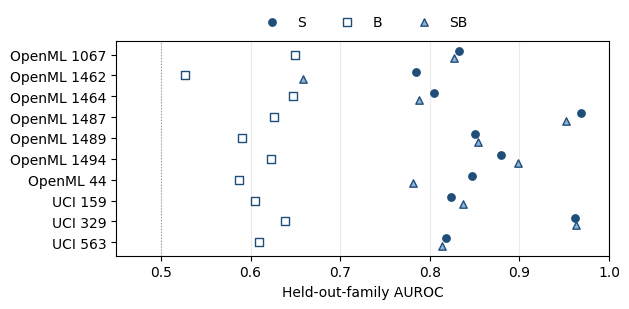

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
fams = [f.replace("openml_", "OpenML ").replace("uci_", "UCI ") for f in per_family.index]
y = np.arange(len(fams))
for i, (view, marker, face) in enumerate([("S", "o", "#1f4e79"), ("B", "s", "white"), ("SB", "^", "#8fb3d9")]):
    ax.scatter(per_family[view], y + (i - 1) * 0.18, marker=marker, facecolor=face, edgecolor="#1f4e79", s=28, label=view, zorder=3)
ax.axvline(0.5, color="0.6", lw=0.8, ls=":")
ax.set_yticks(y); ax.set_yticklabels(fams); ax.invert_yaxis()
ax.set_xlabel("Held-out-family AUROC"); ax.set_xlim(0.45, 1.0); ax.grid(axis="x", color="0.92")
ax.legend(ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()

## 4. By mechanism, deduplicated tables

One mechanism's positives against all negatives, per family, then averaged. This breakdown is descriptive.

In [7]:
dd = s3[(s3.variant == "dd") & s3.view.isin(["S", "B", "SB"])]
groups = {"exact copies": ["exact"], "near copies": ["near"], "scope (L4)": ["l4"], "proxies (L5)": ["l5"]}
rows = {}
for name, mech in groups.items():
    rows[name] = (dd.groupby(["heldout_family", "view"])[["score", "label", "mechanism_group"]]
                    .apply(lambda g: auroc(g.score[g.mechanism_group.isin(mech)], g.score[g.label == 0]))
                    .unstack().mean())
pd.DataFrame(rows).T[["S", "B", "SB"]].round(3)

view,S,B,SB
exact copies,0.893,0.576,0.905
near copies,0.834,0.544,0.828
scope (L4),1.000,0.488,0.986
proxies (L5),0.852,0.875,0.850


## 5. Where to go next

- `results/tables/` and `results/figures/` hold every table and figure as submitted.
- `research/review_response_2026-11-03/round8/R8_RESULTS.json` and `round9/runs/R9_RESULTS.json` hold the targeted reruns, the hidden-scope experiment and the robustness experiments.
- `docs/PAPER_MAP.md` maps each section to its code and outputs.